# LAB 5: MADALINE

## Overview
This notebook is organized into clear labeled sections to make the code easier to follow without changing the original logic.

### Section guide
1. Imports and setup
2. Learning rule and model logic
3. Decision boundary and architecture experiments
4. Results


In [1]:
import numpy as np
import matplotlib.pyplot as plt

def f(z):
    return np.where(z >= 0, 1, -1)

class Madaline:
    """MADALINE Model using the MRI Rule."""
    def __init__(self, n_in=2, m=2, seed=0):
        rng = np.random.default_rng(seed)
        self.W = rng.uniform(-0.5, 0.5, (n_in, m))
        self.b = rng.uniform(-0.5, 0.5, m)
        self.v = np.full(m, 0.5)
        self.b0 = 0.5 * (m - 1)
        self.m = m

    def hidden_in(self, x):
        return x @ self.W + self.b

    def predict(self, X):
        z = f(self.hidden_in(X))
        return f(z @ self.v + self.b0)

    def fit(self, X, t, lr=0.5, max_epochs=200):
        for epoch in range(1, max_epochs + 1):
            changed = False
            for x, ti in zip(X, t):
                z_in = self.hidden_in(x)
                y = f(np.dot(f(z_in), self.v) + self.b0)
                if y == ti:
                    continue
                changed = True
                if ti == 1:
                    j = np.argmin(np.abs(z_in))
                    self.W[:, j] += lr * (1 - z_in[j]) * x
                    self.b[j] += lr * (1 - z_in[j])
                else:
                    for k in np.where(z_in > 0)[0]:
                        self.W[:, k] += lr * (-1 - z_in[k]) * x
                        self.b[k] += lr * (-1 - z_in[k])
            if not changed:
                return epoch
        return max_epochs

# Bipolar dataset
X = np.array([[-1, -1], [-1, 1], [1, -1], [1, 1]])
targets = {"XOR": np.array([-1, 1, 1, -1]), "XNOR": np.array([1, -1, -1, 1])}

print("--- Task 1: Train MADALINE on XOR and XNOR ---")
models = {}
for name, t in targets.items():
    m = Madaline(m=2, seed=0)
    ep = m.fit(X, t)
    pred = m.predict(X)
    models[name] = m
    print(f"{name}: converged in {ep} epochs | accuracy: {(pred == t).mean()*100:.0f}%")

--- Task 1: Train MADALINE on XOR and XNOR ---
XOR: converged in 3 epochs | accuracy: 100%
XNOR: converged in 3 epochs | accuracy: 100%


## Task 2 & 3: Decision boundaries and architecture experiments


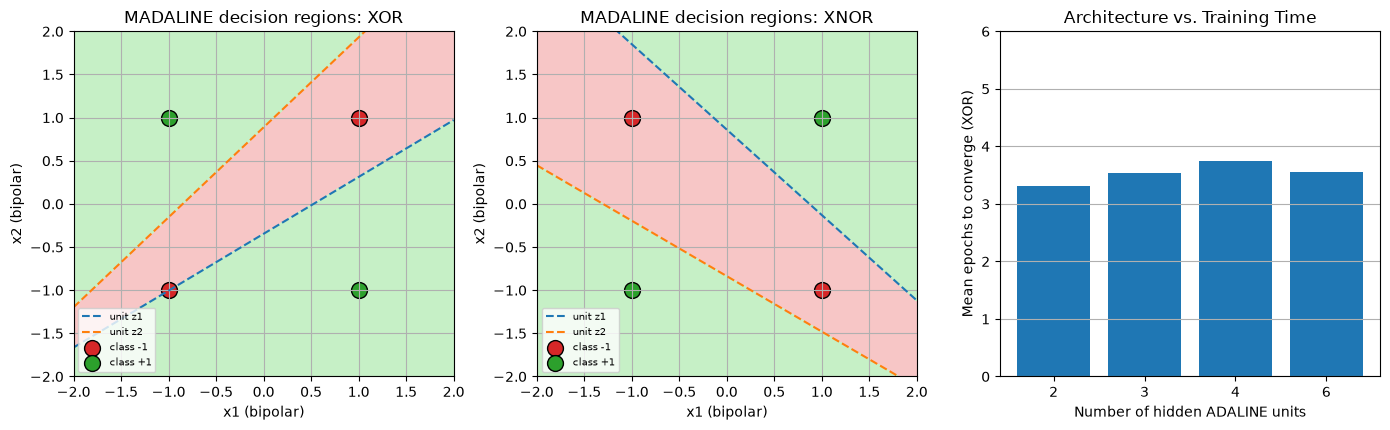

In [2]:
# ---- Task 2 & 3: Decision Boundaries and Architecture Experiments ----
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
grid_x, grid_y = np.meshgrid(np.linspace(-2, 2, 300), np.linspace(-2, 2, 300))
G = np.c_[grid_x.ravel(), grid_y.ravel()]

for ax, (name, md) in zip(axes[:2], models.items()):
    t = targets[name]
    ax.contourf(grid_x, grid_y, md.predict(G).reshape(grid_x.shape), levels=[-2, 0, 2], colors=["#f7c6c6", "#c6f0c6"])
    for j in range(2):
        w, b = md.W[:, j], md.b[j]
        xs = np.linspace(-2, 2, 50)
        ax.plot(xs, -(w[0] * xs + b) / w[1], "--", lw=1.5, label=f"unit z{j+1}")
    ax.scatter(X[t == -1, 0], X[t == -1, 1], c="tab:red", s=130, edgecolors="k", label="class -1")
    ax.scatter(X[t == 1, 0], X[t == 1, 1], c="tab:green", s=130, edgecolors="k", label="class +1")
    ax.set_xlim(-2, 2)
    ax.set_ylim(-2, 2)
    ax.set_title(f"MADALINE decision regions: {name}")
    ax.set_xlabel("x1 (bipolar)")
    ax.set_ylabel("x2 (bipolar)")
    ax.legend(fontsize=7, loc="lower left")
    ax.grid(True)

# Hidden Units Architecture Comparison
ms = [2, 3, 4, 6]
means = []
for m_units in ms:
    eps = [Madaline(m=m_units, seed=s) for s in range(50)]
    means.append(np.mean([e.fit(X, targets["XOR"]) for e in eps]))

axes[2].bar([str(m) for m in ms], means, color="tab:blue")
axes[2].set_ylim(0, 6)
axes[2].set_xlabel("Number of hidden ADALINE units")
axes[2].set_ylabel("Mean epochs to converge (XOR)")
axes[2].set_title("Architecture vs. Training Time")
axes[2].grid(True, axis="y")

plt.tight_layout()
plt.show()